In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width',200,'display.max_columns',60,'display.float_format','{:,.2f}'.format)
OUT='.'
cost_df=pd.read_csv(f'{OUT}/scms_matriks_biaya.csv',index_col=0)
nodes=pd.read_csv(f'{OUT}/scms_node_supply_demand.csv')
supply=nodes[nodes.tipe=='Sumber'].set_index('node').volume_kg.reindex(cost_df.index)
demand=nodes[nodes.tipe=='Tujuan'].set_index('node').volume_kg.reindex(cost_df.columns)
blocked=cost_df.isna().values
M=10*np.nanmax(cost_df.values)
C=np.where(blocked,M,cost_df.values)
a=supply.values.astype(float)
b=demand.values.astype(float)
m,n=C.shape
EPS=1e-9
print(m,n,round(M,2),blocked.sum(),np.isclose(a.sum(),b.sum()))

22 38 3512.1 578 True


In [2]:
def nwcr(C,a,b):
    a=a.copy(); b=b.copy(); X=np.zeros(C.shape); basic=np.zeros(C.shape,bool)
    m,n=C.shape; i=j=0
    while i<m and j<n:
        q=min(a[i],b[j]); X[i,j]=q; basic[i,j]=True
        a[i]-=q; b[j]-=q
        ra=a[i]<=EPS; rb=b[j]<=EPS
        if ra and rb:
            if i<m-1: i+=1
            else: j+=1
        elif ra: i+=1
        else: j+=1
    return X,basic

In [3]:
def drop_line(a,b,i,j,rows,cols):
    if a[i]<=EPS and b[j]<=EPS:
        if rows.sum()>1: rows[i]=False
        else: cols[j]=False
    elif a[i]<=EPS: rows[i]=False
    else: cols[j]=False

def pick_cell(C,a,b,rows,cols,line=None):
    ri=np.where(rows)[0]; ci=np.where(cols)[0]
    if line is None:
        cand=[(C[i,j],-min(a[i],b[j]),i,j) for i in ri for j in ci]
    elif line[0]=='r':
        cand=[(C[line[1],j],-min(a[line[1]],b[j]),line[1],j) for j in ci]
    else:
        cand=[(C[i,line[1]],-min(a[i],b[line[1]]),i,line[1]) for i in ri]
    c,_,i,j=min(cand)
    return i,j

def lcm(C,a,b):
    a=a.copy(); b=b.copy(); X=np.zeros(C.shape); basic=np.zeros(C.shape,bool)
    rows=np.ones(len(a),bool); cols=np.ones(len(b),bool)
    while rows.any() and cols.any():
        i,j=pick_cell(C,a,b,rows,cols)
        q=min(a[i],b[j]); X[i,j]=q; basic[i,j]=True
        a[i]-=q; b[j]-=q
        drop_line(a,b,i,j,rows,cols)
    return X,basic

In [4]:
def penalties(C,rows,cols):
    ri=np.where(rows)[0]; ci=np.where(cols)[0]
    pr={}; pc={}
    for i in ri:
        v=np.sort(C[i,ci]); pr[i]=v[1]-v[0] if len(v)>1 else v[0]
    for j in ci:
        v=np.sort(C[ri,j]); pc[j]=v[1]-v[0] if len(v)>1 else v[0]
    return pr,pc

def vam(C,a,b):
    a=a.copy(); b=b.copy(); X=np.zeros(C.shape); basic=np.zeros(C.shape,bool)
    rows=np.ones(len(a),bool); cols=np.ones(len(b),bool)
    while rows.any() and cols.any():
        pr,pc=penalties(C,rows,cols)
        ir=max(pr,key=pr.get); ic=max(pc,key=pc.get)
        line=('r',ir) if pr[ir]>=pc[ic] else ('c',ic)
        i,j=pick_cell(C,a,b,rows,cols,line)
        q=min(a[i],b[j]); X[i,j]=q; basic[i,j]=True
        a[i]-=q; b[j]-=q
        drop_line(a,b,i,j,rows,cols)
    return X,basic

In [5]:
def hitung_uv(C,basic):
    m,n=C.shape
    u=np.full(m,np.nan); v=np.full(n,np.nan); u[0]=0.0
    stack=[('r',0)]
    while stack:
        t,k=stack.pop()
        if t=='r':
            for j in np.where(basic[k])[0]:
                if np.isnan(v[j]):
                    v[j]=C[k,j]-u[k]; stack.append(('c',j))
        else:
            for i in np.where(basic[:,k])[0]:
                if np.isnan(u[i]):
                    u[i]=C[i,k]-v[k]; stack.append(('r',i))
    return u,v

def cari_siklus(basic,i0,j0):
    m,n=basic.shape
    parent={('r',i0):None}
    queue=[('r',i0)]
    while queue:
        node=queue.pop(0)
        if node==('c',j0): break
        t,k=node
        if t=='r':
            for j in np.where(basic[k])[0]:
                nx=('c',j)
                if nx not in parent: parent[nx]=node; queue.append(nx)
        else:
            for i in np.where(basic[:,k])[0]:
                nx=('r',i)
                if nx not in parent: parent[nx]=node; queue.append(nx)
    path=[]; node=('c',j0)
    while node is not None:
        path.append(node); node=parent[node]
    path=path[::-1]
    edges=[]
    for p,q in zip(path[:-1],path[1:]):
        i=p[1] if p[0]=='r' else q[1]
        j=q[1] if q[0]=='c' else p[1]
        edges.append((i,j))
    return edges

In [6]:
def modi(C,X0,basic0,batas=5000):
    X=X0.copy(); basic=basic0.copy()
    riwayat=[(X*C).sum()]
    for it in range(batas):
        u,v=hitung_uv(C,basic)
        if np.isnan(u).any() or np.isnan(v).any():
            raise ValueError('basis tidak terhubung')
        D=C-u[:,None]-v[None,:]
        D[basic]=0.0
        k=np.argmin(D)
        if D.flat[k]>=-1e-9:
            return X,basic,it,riwayat,D
        i0,j0=divmod(k,C.shape[1])
        edges=cari_siklus(basic,i0,j0)
        L=len(edges)
        minus=[edges[t] for t in range(L) if (L-1-t)%2==0]
        plus=[edges[t] for t in range(L) if (L-1-t)%2==1]
        theta=min(X[e] for e in minus)
        leaving=next(e for e in minus if X[e]<=theta+EPS)
        for e in minus: X[e]-=theta
        for e in plus: X[e]+=theta
        X[i0,j0]=theta
        X[leaving]=0.0
        basic[leaving]=False
        basic[i0,j0]=True
        riwayat.append((X*C).sum())
    raise RuntimeError('batas iterasi tercapai')

In [7]:
awal={'NWCR':nwcr(C,a,b),'LCM':lcm(C,a,b),'VAM':vam(C,a,b)}
akhir={}
for k,(X0,B0) in awal.items():
    akhir[k]=modi(C,X0,B0)
    print(k,'iterasi MODI:',akhir[k][2])

NWCR iterasi MODI: 97
LCM iterasi MODI: 42
VAM iterasi MODI: 16


In [8]:
def biaya_valid(X):
    return (X[~blocked]*C[~blocked]).sum()

baris=[]
for k in awal:
    X0,B0=awal[k]; X1,B1,it,rw,D=akhir[k]
    baris.append({'Metode':k,
        'Sel basis awal':int(B0.sum()),
        'Sel terblokir awal':int(((X0>EPS)&blocked).sum()),
        'Kg terblokir awal':X0[blocked].sum(),
        'Biaya awal valid (USD)':biaya_valid(X0),
        'Biaya awal + Big-M (USD)':(X0*C).sum(),
        'Iterasi MODI':it,
        'Sel terblokir akhir':int(((X1>EPS)&blocked).sum()),
        'Biaya akhir (USD)':(X1*C).sum(),
        'Sel alokasi akhir':int((X1>EPS).sum()),
        'Min reduced cost':D[~B1].min()})
ringkas=pd.DataFrame(baris)
ringkas

,Metode,Sel basis awal,Sel terblokir awal,Kg terblokir awal,Biaya awal valid (USD),Biaya awal + Big-M (USD),Iterasi MODI,Sel terblokir akhir,Biaya akhir (USD),Sel alokasi akhir,Min reduced cost
0,NWCR,59,37,"2,413,372.00","72,073,870.92","8,548,077,672.12",97,0,"54,461,845.22",59,0.14
1,LCM,59,8,"275,944.00","62,022,909.36","1,031,165,831.76",42,0,"54,461,845.22",59,0.14
2,VAM,59,0,0.00,"56,691,683.86","56,691,683.86",16,0,"54,461,845.22",59,0.14


In [9]:
aktual=pd.read_csv(f'{OUT}/scms_data_bersih.csv').biaya_freight_usd.sum()
akh=ringkas['Biaya akhir (USD)'].values
print(f'Biaya aktual data : {aktual:,.0f}')
print('Biaya akhir ketiga metode sama:',np.allclose(akh,akh[0]))
print(f'Biaya optimal     : {akh.min():,.0f}')
print(f'Penghematan vs aktual: {1-akh.min()/aktual:.2%}')
for k in awal:
    X0=awal[k][0]
    print(k,f'awal vs optimal: {biaya_valid(X0)/akh.min()-1:.2%}' if (X0[blocked]>0).sum()==0 else f'awal tidak layak ({X0[blocked].sum()/a.sum():.1%} berat di rute terlarang)')

Biaya aktual data : 67,933,960
Biaya akhir ketiga metode sama: True
Biaya optimal     : 54,461,845
Penghematan vs aktual: 19.83%
NWCR awal tidak layak (12.3% berat di rute terlarang)
LCM awal tidak layak (1.4% berat di rute terlarang)
VAM awal vs optimal: 4.09%


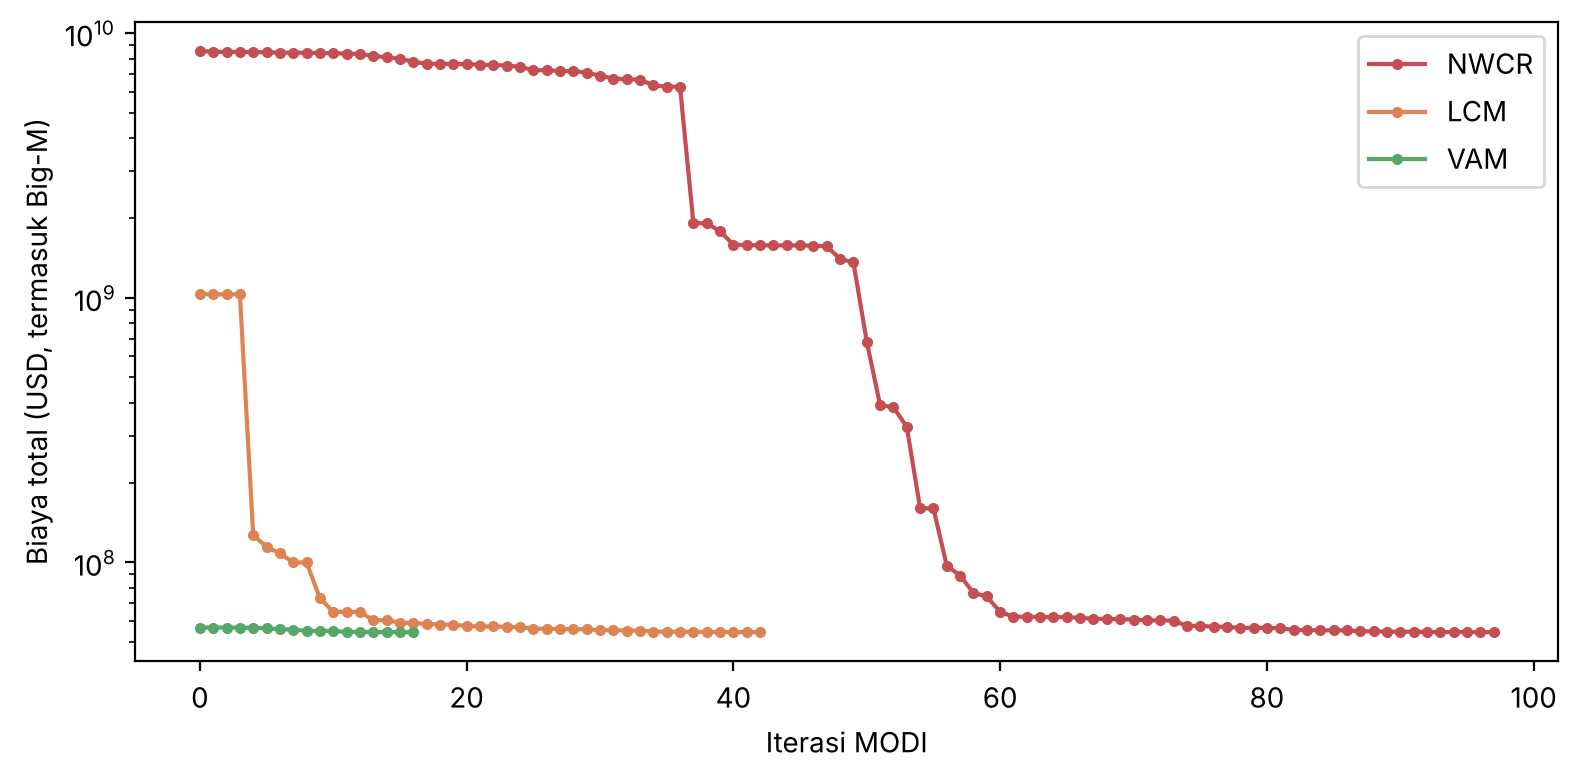

In [10]:
fig,ax=plt.subplots(figsize=(8,4))
for k,col in zip(akhir,['#c44e52','#dd8452','#55a868']):
    ax.plot(range(len(akhir[k][3])),akhir[k][3],marker='o',ms=3,label=k,color=col)
ax.set_yscale('log'); ax.set_xlabel('Iterasi MODI'); ax.set_ylabel('Biaya total (USD, termasuk Big-M)'); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
def tampil(X):
    return pd.DataFrame(X,index=cost_df.index,columns=cost_df.columns).round(0).astype(int)
tampil(akhir['VAM'][0])

,Nigeria,Zambia,Mozambique,South Africa,Zimbabwe,Côte d'Ivoire,Tanzania,Uganda,Rwanda,Vietnam,Haiti,Ethiopia,Cameroon,Kenya,Ghana,Namibia,Swaziland,"Congo, DRC",Malawi,Guyana,Burundi,Botswana,Dominican Republic,South Sudan,Benin,Pakistan,Guatemala,Sudan,Togo,Angola,Libya,Sierra Leone,Lesotho,Mali,Liberia,Guinea,Afghanistan,Senegal
sumber,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
SCMS RDC,3856657,2635348,1946462,0,1526030,1255014,1362985,0,823760,0,0,0,0,0,119313,72936,0,59902,0,0,28714,0,0,17754,12015,0,0,0,0,0,1783,0,0,0,0,0,0,21
Aurobindo (India),0,0,0,1419467,0,0,0,0,0,0,0,34472,0,0,0,0,63752,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Mylan/Matrix (India),0,0,0,0,0,0,0,706291,0,0,0,0,0,0,0,0,0,0,57180,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Alere/Inverness (Japan),0,0,401403,0,0,0,0,0,0,0,254718,0,0,0,0,0,0,0,0,0,0,25047,0,0,0,7998,0,0,0,0,0,1719,856,725,0,32,0,0
Hetero (India),0,0,0,0,0,0,0,0,0,578453,73868,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2325,0,0,0,0,0,0,0,0,0
Cipla (India),0,0,0,278286,0,0,0,111430,0,0,230484,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Strides (India),0,0,0,0,0,0,0,393004,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AbbVie/Abbott (Eropa),0,0,0,0,0,0,0,0,0,0,0,0,196671,0,0,0,0,0,0,24758,0,0,23097,0,0,0,0,0,0,1914,0,0,0,0,0,0,0,0
Trinity Biotech (Irlandia),0,0,0,0,0,0,0,31013,0,0,0,0,0,168433,0,0,0,0,0,10732,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [12]:
with pd.ExcelWriter(f'{OUT}/hasil_nwcr_lcm_vam_modi.xlsx') as w:
    ringkas.to_excel(w,sheet_name='Ringkasan',index=False)
    for k in awal:
        tampil(awal[k][0]).to_excel(w,sheet_name=f'{k}_awal')
        tampil(akhir[k][0]).to_excel(w,sheet_name=f'{k}_MODI')

## Peta rute pengiriman (OpenStreetMap)

Butuh `buat_peta_rute.py` di folder yang sama dengan notebook. Peta berupa satu file HTML interaktif: pilih NWCR / LCM / VAM, solusi awal atau setelah MODI, klik penanda untuk menyorot rute. Perlu koneksi internet untuk memuat tile OpenStreetMap.

In [ ]:
from buat_peta_rute import buat_peta
from IPython.display import IFrame

buat_peta(awal, akhir, cost_df, C, blocked, a, b, aktual, 'peta_rute_scms.html')
IFrame('peta_rute_scms.html', width='100%', height=650)